# Experiment 16: Number of hidden layers

Card: [exp16_depth.md](../../experiments/exp16_depth.md)


In [ ]:
import os
import sys
from time import perf_counter

import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp16_depth"
EMB_DIM = 12  # picked in exp03
LR = 1e-2
WIDTH, DROPOUT = 64, 0.1  # picked in exp15
if SMOKE:
    EXPERIMENT = "ashrae-mlp-depth-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    DEPTHS = [3]
    # (experiment, session, dropout) of the reused 2-layer runs; None: the latest session
    REFERENCE = (
        "ashrae-mlp-small-width-dropout-smoke",
        None,
        0.3,
    )  # stands in for dropout 0.1
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-depth"
    TRAIN = (
        True  # set False with SESSION to re-read a finished session without training
    )
    SESSION = None
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    DEPTHS = [1, 3, 4]
    REFERENCE = (
        "ashrae-mlp-small-width-dropout",
        "2026-10-13 09:06:41",
        DROPOUT,
    )  # exp15
    FIGURE = "../../figures/exp16_depth.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/13 10:01:49 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-depth' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-depth', session 2026-10-13 10:01:49


## Training


In [2]:
def at_best(run_id):
    """A run's scores at its best validation epoch and its per-epoch curves; a diverged run scores inf."""
    val = np.array(experiment.history(run_id, "val_rmsle"))
    train = np.array(experiment.history(run_id, "train_rmsle"))
    if not np.isfinite(val).all():
        return {"val": np.inf, "val_curve": val, "train_curve": train}
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": experiment.history(run_id, "val_rmsle_clean")[b],
        "train": train[b],
        "val_last": val[-1],
        "val_clean_last": experiment.history(run_id, "val_rmsle_clean")[-1],
        "train_last": train[-1],
        "epoch_seconds": np.mean(experiment.history(run_id, "epoch_seconds")),
        "val_curve": val,
        "train_curve": train,
    }


def session_runs(name, session):
    """Finished runs of one session of another notebook (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[name], filter_string="attributes.status = 'FINISHED'"
    )
    runs = runs.rename(columns=lambda c: c.removeprefix("tags."))
    return runs[runs.session == (session or runs.session.max())]


def scores():
    own = experiment.runs().rename(columns=lambda c: c.removeprefix("tags."))
    own = own[own.status == "FINISHED"]  # an interrupted run is retrained
    name, session, p = REFERENCE
    ref = session_runs(name, session)
    ref = ref[
        (ref["params.lr"].astype(float) == LR)
        & (ref.width.astype(int) == WIDTH)
        & (ref.dropout.astype(float) == p)
    ]
    runs = pd.concat([own, ref.assign(layers=2)])[["run_id", "layers", "fold"]]
    runs = (
        runs[runs.fold.isin(FOLD_NAMES)]
        .assign(layers=lambda r: r.layers.astype(int))
        .reset_index(drop=True)
    )
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    results = pd.concat([runs, scored], axis=1)
    results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60
    return results


class CleanRMSLE(L.Callback):
    """Logs validation RMSLE on the clean rows after every epoch, so it can be read at the best epoch."""

    def __init__(self, loader, y):
        self.loader, self.y = loader, y

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("val_rmsle_clean", rmsle(self.y, predict(model, self.loader)))


class EpochSeconds(L.Callback):
    """Logs the wall time of each epoch's training batches, without validation."""

    def on_train_epoch_start(self, trainer, model):
        self.start = perf_counter()

    def on_validation_start(self, trainer, model):
        if not trainer.sanity_checking:
            self.seconds = perf_counter() - self.start

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("epoch_seconds", self.seconds)

In [3]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        clean = ~val_df.anomaly.to_numpy()
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "clean": (
                make_loaders(train_df, val_df[clean], X_train, X_val[clean])[1],
                np.log1p(val_df.meter_reading.to_numpy(dtype="float32")[clean]),
            ),
        }
    del df
    n_features = X_train.shape[1]
    done = (
        set()
        if SESSION is None
        else set(
            scores()
            .query("layers != 2")[["layers", "fold"]]
            .itertuples(index=False, name=None)
        )
    )

    for n_layers in DEPTHS:
        for fold, d in folds.items():
            if (n_layers, fold) in done:
                continue
            experiment.fit(
                lambda: MeterMLP(
                    n_features,
                    n_buildings,
                    emb_dim=EMB_DIM,
                    batch_norm=True,
                    dropout=DROPOUT,
                    width=WIDTH,
                    n_layers=n_layers,
                ),
                *d["loaders"],
                run_name=f"mlp_4out_emb_bn | layers {n_layers} | {fold}",
                epochs=EPOCHS,
                lr=LR,
                callbacks=[
                    CleanRMSLE(*d["clean"]),
                    EpochSeconds(),
                    # stops a diverged run only: patience never runs out
                    EarlyStopping("val_rmsle", patience=EPOCHS, check_finite=True),
                ],
                tags={
                    "fold": fold,
                    "model": "mlp_4out_emb_bn",
                    "layers": str(n_layers),
                    "width": str(WIDTH),
                    "dropout": f"{DROPOUT:g}",
                },
                params={
                    "n_train": N_TRAIN,
                    "n_val": N_VAL,
                    "emb_dim": EMB_DIM,
                    "width": WIDTH,
                    "dropout": DROPOUT,
                    "n_layers": n_layers,
                },
            )

mlp_4out_emb_bn | layers 1 | Jan–Mar: 100%|██████████| 19560/19560 [01:13<00:00, 266.13batch/s, epoch 40, val 1.4147, best 1.4037 at 14]
mlp_4out_emb_bn | layers 1 | Apr–Jun: 100%|██████████| 19560/19560 [01:06<00:00, 292.34batch/s, epoch 40, val 1.1998, best 1.1998 at 40]
mlp_4out_emb_bn | layers 1 | Jul–Sep: 100%|██████████| 19560/19560 [01:07<00:00, 291.17batch/s, epoch 40, val 1.0298, best 1.0298 at 40]
mlp_4out_emb_bn | layers 1 | Oct–Dec: 100%|██████████| 19560/19560 [01:07<00:00, 290.69batch/s, epoch 40, val 1.0882, best 1.0821 at 28]
mlp_4out_emb_bn | layers 3 | Jan–Mar: 100%|██████████| 19560/19560 [01:31<00:00, 213.39batch/s, epoch 40, val 1.3811, best 1.3769 at 25]
mlp_4out_emb_bn | layers 3 | Apr–Jun: 100%|██████████| 19560/19560 [01:34<00:00, 207.83batch/s, epoch 40, val 1.1984, best 1.1937 at 35]
mlp_4out_emb_bn | layers 3 | Jul–Sep: 100%|██████████| 19560/19560 [01:32<00:00, 210.50batch/s, epoch 40, val 1.0226, best 1.0027 at 34]
mlp_4out_emb_bn | layers 3 | Oct–Dec: 100

## Results


In [ ]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "val_last": f"average at epoch {EPOCHS}",
    "val_clean_last": f"average at epoch {EPOCHS}, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
by_setup = results.groupby("layers")[["val", *columns]].mean()
table = results.pivot_table(index="layers", columns="fold", values="val")[FOLD_NAMES]
table["average"] = by_setup.val
table = table.join(by_setup[list(columns)].rename(columns=columns))
display(
    table.round(3).rename_axis(columns="RMSLE at the best epoch, all rows unless noted")
)

best = by_setup.val.idxmin()
print("best depth:", best)

MLflow session 2026-10-13 10:01:49: 16 runs, with the reused ones


"RMSLE at the best epoch, all rows unless noted",Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",average at epoch 40,"average at epoch 40, clean rows",best epoch,training at best epoch,training at epoch 40,seconds per epoch,minutes to best epoch
layers,,,,,,,,,,,,,
1,1.404,1.200,1.030,1.082,1.179,0.921,1.183,0.921,30.50,0.843,0.837,1.548,0.776
2,1.379,1.188,1.001,1.081,1.162,0.907,1.165,0.912,27.75,0.815,0.807,1.926,0.890
3,1.377,1.194,1.003,1.084,1.164,0.918,1.175,0.927,27.00,0.814,0.805,2.122,0.957
4,1.383,1.194,1.009,1.088,1.169,0.919,1.180,0.931,29.75,0.811,0.805,2.451,1.214


best depth: 2


In [5]:
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SHADES = ["#9ec5f0", "#5b9be3", "#174e94"]  # light to dark: fewest to most layers

CURVES = [
    ("val_curve", "validation RMSLE, all rows"),
    ("train_curve", "training RMSLE"),
]


def draw(ax, groups, key, label, title):
    for name, runs, color, ls, alpha, zorder in groups:
        # mean over folds; a diverged run is shorter
        curve = pd.DataFrame(runs[key].tolist()).mean()
        ax.plot(
            np.arange(1, len(curve) + 1),
            curve,
            lw=2,
            color=color,
            ls=ls,
            alpha=alpha,
            zorder=zorder,
            label=name,
        )
    ax.set(xlabel="epoch", ylabel=label)
    ax.set_title(title, loc="left", color=TEXT, fontsize=9)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)

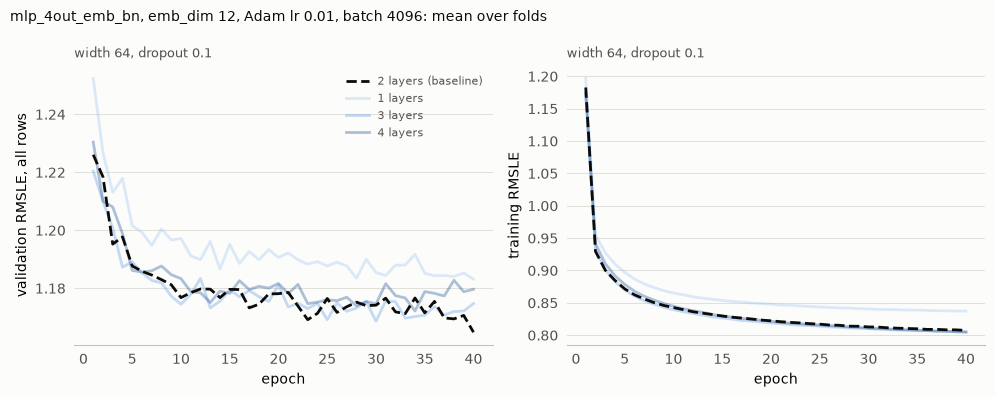

In [ ]:
# The winning depth in full color, the others faded
alpha = lambda n: 1.0 if n == best else 0.35
groups = [
    ("2 layers (baseline)", results.query("layers == 2"), INK, "--", alpha(2), 3)
] + [
    (f"{n} layers", runs, SHADES[i], "-", alpha(n), 2)
    for i, (n, runs) in enumerate(results.query("layers != 2").groupby("layers"))
]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor=SURFACE)
for ax, (key, label) in zip(axes, CURVES):
    draw(ax, groups, key, label, f"width {WIDTH}, dropout {DROPOUT:g}")
axes[0].legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, Adam lr {LR:g}, batch 4096: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
fig.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("layers != 2").run_id:
        experiment.client.log_artifact(run_id, FIGURE)